# Building a CSS memory circuit with LocalASC

This walkthrough starts from the project's `Hx` and `Hz` parity-check matrices, generates a valid CNOT schedule, and builds X- and Z-basis Stim memory circuits. We use the small `12_4` example so the full workflow is practical to run.

## Workflow

1. Load the binary CSS parity-check matrices and verify their dimensions and commutation condition, `Hx @ Hz.T = 0 (mod 2)`.
2. Generate a CNOT schedule with LocalASC and inspect its check-to-data interactions.
3. Use that same schedule to build memory circuits in both bases, then inspect the Stim circuits and their detector error models.

The schedule-generation call uses the repository's CP-SAT scheduler. For larger codes it may take longer; the timeout can be increased.

## 1. Imports and project paths

In [22]:
import sys
from pathlib import Path
import numpy as np
import stim

# Find the repository root
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "codes").is_dir() and (path / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the LocASC repository root from the current directory.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.LocalASC.circuit_builder.circuit_builder import (
    build_CSS_memory_circuit,
    load_schedule,
    rank2_rref,
)
from src.LocalASC.circuit_builder.noise import add_circuit_level_noise
from src.LocalASC.scheduling.localASC_scheduler import generate_schedule

## 2. Load and check `Hx` and `Hz`

Each row represents one stabilizer check and each column one data qubit. The matrices must have the same number of columns, contain binary entries, and commute across X/Z checks.

In [23]:
code_dir = project_root / "codes" / "12_4"
hx_path = code_dir / "TT_12_4_d2_Hx.txt"
hz_path = code_dir / "TT_12_4_d2_Hz.txt"

Hx = np.loadtxt(hx_path, dtype=np.uint8)
Hz = np.loadtxt(hz_path, dtype=np.uint8)

if Hx.ndim != 2 or Hz.ndim != 2 or Hx.shape[1] != Hz.shape[1]:
    raise ValueError(f"Expected 2D Hx and Hz with matching column counts; got {Hx.shape} and {Hz.shape}.")
if not np.isin(Hx, [0, 1]).all() or not np.isin(Hz, [0, 1]).all():
    raise ValueError("Parity-check matrices must contain only 0 and 1.")
if np.any((Hx @ Hz.T) % 2):
    raise ValueError("Hx and Hz do not commute over GF(2); this is not a valid CSS code.")

rank_x, _, _ = rank2_rref(Hx)
rank_z, _, _ = rank2_rref(Hz)
n = Hx.shape[1]
k = n - rank_x - rank_z
print(f"Hx: {Hx.shape}  |  Hz: {Hz.shape}")
print(f"Data qubits n={n}; ranks=({rank_x}, {rank_z}); encoded qubits k={k}")
print("CSS commutation check passed.")

Hx: (6, 12)  |  Hz: (6, 12)
Data qubits n=12; ranks=(4, 4); encoded qubits k=4
CSS commutation check passed.


## 3. Generate and inspect a CNOT schedule for syndrome extraction

A sydrome extraction schedule assigns each non-zero entry in each matrix a TICK. A check cannot use one data qubit twice in a tick, and a data qubit cannot participate in two checks at the same tick. We start at the maximum Tanner Graph degree which is a lower bound on the depth.

In [24]:
max_check_weight = int(max(Hx.sum(axis=1).max(), Hz.sum(axis=1).max()))
max_data_degree = int((Hx.sum(axis=0) + Hz.sum(axis=0)).max())
target_depth = max(max_check_weight, max_data_degree)

schedule_path = project_root / "results" / "schedules" / "walkthrough_12_4.csv"
schedule_path.parent.mkdir(parents=True, exist_ok=True)
success, status = generate_schedule(
    Hx,
    Hz,
    target_depth,
    str(schedule_path),
    solver_tlim=60,
)
if not success:
    raise RuntimeError(
        f"Could not generate a valid schedule at depth {target_depth} (solver status: {status}). "
        "Try increasing target_depth or solver_tlim."
    )

schedule_rows = load_schedule(schedule_path)

#Verification of schedule correctness.
expected_interactions = int(Hx.sum() + Hz.sum())
expected_edges = {
    ("X", check, int(data_qubit))
    for check in range(Hx.shape[0])
    for data_qubit in np.flatnonzero(Hx[check])
} | {
    ("Z", check, int(data_qubit))
    for check in range(Hz.shape[0])
    for data_qubit in np.flatnonzero(Hz[check])
}
actual_edges = {(kind, check, data_qubit) for kind, check, data_qubit, _ in schedule_rows}
if len(schedule_rows) != expected_interactions or actual_edges != expected_edges:
    raise ValueError("Schedule interactions do not exactly match the nonzero entries of Hx and Hz.")

# Verify that no data qubit is assigned more than one interaction at a tick.
qubit_ticks = [(data_qubit, tick) for _, _, data_qubit, tick in schedule_rows]
if len(qubit_ticks) != len(set(qubit_ticks)):
    raise ValueError("The schedule assigns a data qubit to multiple checks at the same tick.")

print(f"Scheduler status: {status}; depth: {target_depth}")
print(f"Saved schedule: {schedule_path.relative_to(project_root)}")
print(f"First schedule rows: {schedule_rows[:8]}")

Scheduler status: OPTIMAL; depth: 6
Saved schedule: results/schedules/walkthrough_12_4.csv
First schedule rows: [('X', 0, 0, 0), ('X', 0, 1, 4), ('X', 0, 2, 5), ('X', 0, 5, 2), ('X', 0, 6, 3), ('X', 0, 7, 1), ('X', 1, 0, 4), ('X', 1, 1, 3)]


## 4. Build memory circuits in both bases

`build_CSS_memory_circuit` uses one ancilla per check, repeats the scheduled syndrome-extraction rounds, measures the data in the requested basis, and appends detectors and logical observables. The same schedule works for both experiments.

In [25]:
rounds = 2 #Choose the number of syndrome extraction rounds
circuit_x = build_CSS_memory_circuit(Hx, Hz, schedule_path, basis="X", rounds=rounds)
circuit_z = build_CSS_memory_circuit(Hx, Hz, schedule_path, basis="Z", rounds=rounds)

for basis, circuit in (("X", circuit_x), ("Z", circuit_z)):
    if circuit.num_qubits != n + Hx.shape[0] + Hz.shape[0]:
        raise ValueError(f"Unexpected qubit count in {basis}-basis circuit: {circuit.num_qubits}.")
    if circuit.num_detectors == 0 or circuit.num_observables != k:
        raise ValueError(
            f"Unexpected detector/observable counts in {basis}-basis circuit: "
            f"{circuit.num_detectors} detectors, {circuit.num_observables} observables."
        )
    # Constructing the DEM checks that the noiseless detector parities are deterministic.
    detector_error_model = circuit.detector_error_model()
    print(
        f"{basis}-basis: {circuit.num_qubits} qubits, {circuit.num_measurements} measurements, "
        f"{circuit.num_detectors} detectors, {circuit.num_observables} observables; "
        f"DEM has {detector_error_model.num_detectors} detectors."
    )

X-basis: 24 qubits, 36 measurements, 24 detectors, 4 observables; DEM has 24 detectors.
Z-basis: 24 qubits, 36 measurements, 24 detectors, 4 observables; DEM has 24 detectors.


## 5. Visualize the generated Stim circuit

Render the Z-basis memory circuit as a Stim timeline diagram.

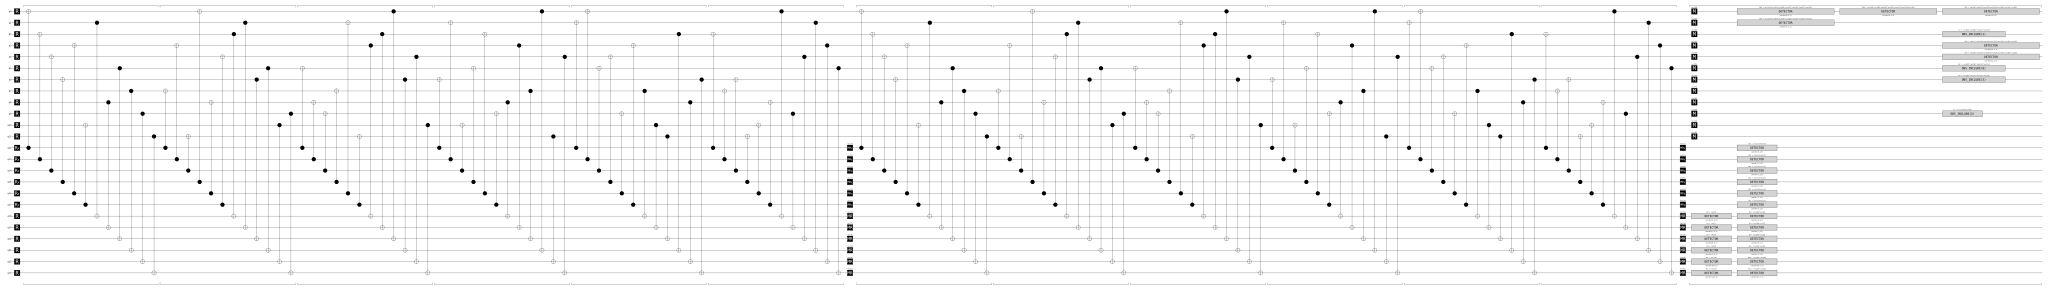

In [26]:
circuit_z.diagram("timeline-svg")

## 6. Add circuit-level noise

The project's helper adds gate, measurement, reset, and idle noise to the scheduled circuit. This is the noisy input one would pass to a decoder or a Sinter experiment; no sampling is started in this walkthrough.

In [27]:
physical_error_rate = 1e-3
noisy_circuit_z = add_circuit_level_noise(
    circuit_z,
    p1q=physical_error_rate,
    p2q=physical_error_rate,
    p_meas=physical_error_rate,
)
noisy_dem_z = noisy_circuit_z.detector_error_model(decompose_errors=True, ignore_decomposition_failures=True)
print(f"Noisy Z-basis circuit: {len(noisy_circuit_z)} instructions")
print(f"Noisy detector error model: {noisy_dem_z.num_detectors} detectors, {noisy_dem_z.num_errors} error mechanisms")

Noisy Z-basis circuit: 89 instructions
Noisy detector error model: 24 detectors, 659 error mechanisms


If the circuit is satisfactory, then it can be saved easily

In [28]:
circuit_path = project_root / "results" / "circuits" / "walkthrough_z_circuit.stim"

circuit_z.to_file(circuit_path)